In [43]:
!python -V

Python 3.13.18


# Zaimportowanie Bibliotek

In [1]:
import copy
import random
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)
import kagglehub

# Przygotowanie notebooka

In [2]:
SEED = 42

# Python
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch — CPU i GPU
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Bardziej powtarzalne operacje na GPU
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
# konfiguracja urządzenia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Pobieranie Danych

In [4]:
path = kagglehub.dataset_download("alexandrepetit881234/egyptian-hieroglyphs")
print("Path to dataset files:", path)

100%|██████████| 10.4M/10.4M [00:01<00:00, 6.80MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/alexandrepetit881234/egyptian-hieroglyphs/versions/1


In [5]:
df_train = pd.read_csv(path + '/train/_annotations.csv')
df_val = pd.read_csv(path +'/valid/_annotations.csv')
df_test = pd.read_csv(path + '/test/_annotations.csv')

In [6]:
df_train.head()

,filename,width,height,class,xmin,ymin,xmax,ymax
0,nile-fish-7-_jpg.rf.31e4278980878c47a1e6a2f8dd...,640,640,Nile_Fish,375,319,512,454
1,Her-8-_jpg.rf.32bcf63f4ae4d6aea53cea5b9c0059b4...,640,640,Her,211,247,368,339
2,composite_bow-34-_jpg.rf.33153e63f7158777c50d4...,640,640,Composite_Bow,158,183,336,282
3,snake-6-_jpg.rf.32ac52ece4bcc06b1ead936693df17...,640,640,Snake,181,351,318,506
4,king-26-_jpg.rf.329a5a8e366f4fe2e3a3dca88524cc...,640,640,King,218,290,339,524


In [7]:
data_dirs = {
    "train": path + '/train',
    "validation": path + '/valid',
    "test": path + '/test',
}

In [8]:
datasets = {
    "train": (df_train, Path(data_dirs['train'])),
    "validation": (df_val, Path(data_dirs['validation'])),
    "test": (df_test, Path(data_dirs['test'])),
}

# Dummy Classifier

In [9]:
y_train = df_train["class"].astype(str)
y_val = df_val["class"].astype(str)

dummy_model = DummyClassifier(strategy="most_frequent")

# Trenowanie i pomiar czasu
start_time = perf_counter()
dummy_model.fit(np.zeros((len(y_train), 1)), y_train)
training_time = perf_counter() - start_time

# Predykcje na validation
start_time = perf_counter()
y_pred_dummy = dummy_model.predict(np.zeros((len(y_val), 1)))
prediction_time = perf_counter() - start_time

print("TRIVIAL BASELINE – DummyClassifier")
print("-" * 45)
print(f"Najczęściej występująca klasa: {dummy_model.classes_[np.argmax(dummy_model.class_prior_)]}")
print(f"Liczba próbek train: {len(y_train)}")
print(f"Liczba próbek validation: {len(y_val)}")

print("\nMETRYKI VALIDATION")
print(f"Accuracy:        {accuracy_score(y_val, y_pred_dummy):.4f}")
print(f"Macro F1-score:  {f1_score(y_val, y_pred_dummy, average='macro', zero_division=0):.4f}")
print(f"Macro precision: {precision_score(y_val, y_pred_dummy, average='macro', zero_division=0):.4f}")
print(f"Macro recall:    {recall_score(y_val, y_pred_dummy, average='macro', zero_division=0):.4f}")

print("\nCZAS")
print(f"Training time:   {training_time:.6f} s")
print(f"Prediction time: {prediction_time:.6f} s")
print(f"Combined time: {training_time + prediction_time:.6f} s")

TRIVIAL BASELINE – DummyClassifier
---------------------------------------------
Najczęściej występująca klasa: Book
Liczba próbek train: 2723
Liczba próbek validation: 778

METRYKI VALIDATION
Accuracy:        0.0051
Macro F1-score:  0.0001
Macro precision: 0.0001
Macro recall:    0.0105

CZAS
Training time:   0.005693 s
Prediction time: 0.001749 s
Combined time: 0.007442 s


# Baseline

In [10]:
# Parametry eksperymentu
IMAGE_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001
PADDING = 0.10

class_names = sorted(df_train["class"].astype(str).unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

print("Liczba klas:", len(class_names))
print("Urządzenie:", device)

Liczba klas: 95
Urządzenie: cpu


Zastosowany preprocessing:
1. Przycięcie obrazu na podstawie bounding boxów z pliku _annotations.csv, z niewielkim marginesem. Pozwala ograniczyć nadmiarowe tło i skupić model na właściwym hieroglifie, zachowując jednocześnie jego istotne fragmenty.

2. Zmiana rozmiaru do 64 × 64 px z zachowaniem proporcji obrazu. Ogranicza koszt obliczeniowy i skraca czas treningu na CPU, przy zachowaniu podstawowych cech kształtu hieroglifów.

3. Konwersja do tensora i normalizacja wartości pikseli do zakresu [-1, 1]. Konwersja umożliwia przetwarzanie obrazów w PyTorch, natomiast normalizacja zapewnia jednolitą skalę danych wejściowych, ułatwiając optymalizację modelu.

In [11]:
class HieroglyphDataset(Dataset):

    def __init__(self, dataframe, image_dir, class_to_idx,
                 image_size, padding):

        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.class_to_idx = class_to_idx
        self.image_size = image_size
        self.padding = padding

        self.mean = [0.5, 0.5, 0.5]
        self.std = [0.5, 0.5, 0.5]

        # Kontrola etykiet
        unknown_classes = set(self.df["class"].astype(str)) - set(class_to_idx)

        if unknown_classes:
            raise ValueError(f"Nieznane klasy: {unknown_classes}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = self.image_dir / row["filename"]

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        # Bounding box
        xmin = float(row["xmin"])
        ymin = float(row["ymin"])
        xmax = float(row["xmax"])
        ymax = float(row["ymax"])

        # Margines wokół hieroglifu
        box_width = xmax - xmin
        box_height = ymax - ymin

        pad_x = box_width * self.padding
        pad_y = box_height * self.padding

        xmin = max(0, int(xmin - pad_x))
        ymin = max(0, int(ymin - pad_y))
        xmax = min(width, int(xmax + pad_x))
        ymax = min(height, int(ymax + pad_y))

        if xmax <= xmin or ymax <= ymin:
            raise ValueError(f"Nieprawidłowy bounding box: {image_path}")

        # Przycięcie obrazu
        image = image.crop((xmin, ymin, xmax, ymax))

        # Zmiana rozmiaru z zachowaniem proporcji
        image = ImageOps.pad(
            image,
            (self.image_size, self.image_size),
            method=Image.Resampling.BILINEAR,
            color=(255, 255, 255)
        )

        # Konwersja do tensora i normalizacja do [-1, 1]
        image = np.asarray(image, dtype=np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)

        image = (image - 0.5) / 0.5

        label = self.class_to_idx[str(row["class"])]

        return image, label


# Utworzenie zbiorów i DataLoaderów

In [12]:
train_dataset = HieroglyphDataset(
    df_train,
    data_dirs["train"],
    class_to_idx,
    IMAGE_SIZE,
    PADDING
)

val_dataset = HieroglyphDataset(
    df_val,
    data_dirs["validation"],
    class_to_idx,
    IMAGE_SIZE,
    PADDING
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

In [13]:
# Kontrola wymiarów
images, labels = next(iter(train_loader))

print("Kształt batcha:", images.shape)
print("Kształt etykiet:", labels.shape)

Kształt batcha: torch.Size([32, 3, 64, 64])
Kształt etykiet: torch.Size([32])


## Kontrola wyników preprocessingu

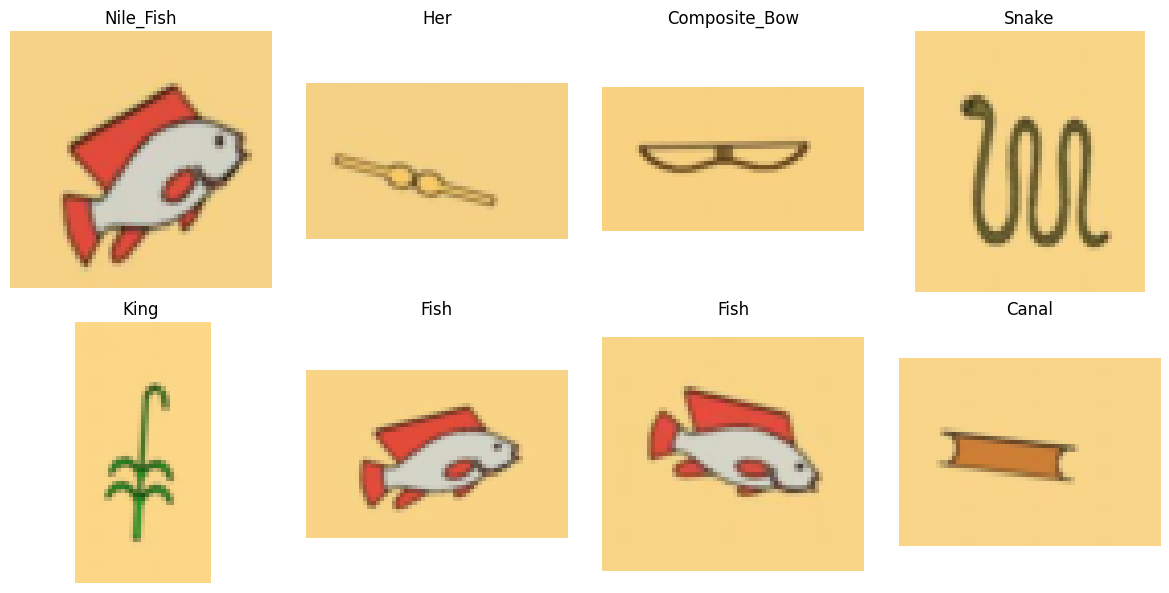

In [14]:
def show_preprocessed_images(dataset, n=8):

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    axes = axes.flatten()

    for i in range(n):
        image, label = dataset[i]

        # Odwrócenie normalizacji
        image = image * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()

        axes[i].imshow(image)
        axes[i].set_title(class_names[label])
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


show_preprocessed_images(train_dataset)

# Przygotowanie Modelu

Uzasadnienie wyboru modelu i hiperparametrów
- Architektura CNN: wybrano trzy bloki konwolucyjne ze stopniwo zwiększającą się liczbą filtrów (16, 32, 64), aby uczyć model rozpoznawania coraz bardziej złożonych cech obrazu, przy zachowaniu umiarkowanej złożoności obliczeniowej. Zastosowano konwolucję 3 × 3 i MaxPooling 2 × 2, ponieważ małe filtry dobrze sprawdzają się w wykrywaniu lokalnych wzorców, natomiast pooling zmniejsza wymiary map cech i ogranicza liczbę obliczeń.
- Adaptive Average Pooling (1 × 1): sprowadza feature maps do stałego rozmiaru niezależnie od ich wymiarów, upraszczając warstwę klasyfikacyjną.
- Dropout (0.3): ogranicza ryzyko przeuczenia poprzez losowe pomijanie części neuronów podczas treningu.
- CrossEntropyLoss: często używana funkcja straty dla wieloklasowej klasyfikacji.
- Adam (learning rate = 0.001): wybrano popularny optymalizator adaptacyjny, który dostosowuje wielkość aktualizacji wag i zapewnia stabilny początek treningu bez konieczności ręcznego dostrajania learning rate.
- Batch size = 32: kompromis między stabilnością aktualizacji wag a zapotrzebowaniem na pamięć i czas obliczeń.
- 20 epok: przyjęto jako początkowy budżet treningowy, pozwalający modelowi wielokrotnie przejść przez zbiór treningowy.

In [16]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            # Blok 1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Blok 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Blok 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = SimpleCNN(num_classes=len(class_names)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(model)
print(f"Liczba parametrów: {sum(p.numel() for p in model.parameters()):,}")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=95, bias=True)
  )
)
Liczba parametrów: 29,759


# Trening Modelu CNN

In [17]:
def evaluate_model(model, loader):

    model.eval()

    y_true = []
    y_pred = []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        average="macro",
        zero_division=0
    )

    return avg_loss, macro_f1, y_true, y_pred


history = {
    "train_loss": [],
    "val_loss": [],
    "val_macro_f1": []
}

best_f1 = -1
best_state = None
best_epoch = 0

training_start = perf_counter()

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    val_loss, val_f1, _, _ = evaluate_model(model, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_f1)

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val macro F1: {val_f1:.4f}"
    )

training_time = perf_counter() - training_start

# Przywrócenie najlepszych wag
model.load_state_dict(best_state)

print("\nTrening zakończony.")
print(f"Najlepsza epoka: {best_epoch}")
print(f"Najlepsze validation macro F1: {best_f1:.4f}")
print(f"Czas treningu wraz z walidacją: {training_time:.2f} s")


Epoch [1/20] Train loss: 4.5322 | Val loss: 4.3773 | Val macro F1: 0.0013
Epoch [2/20] Train loss: 4.1210 | Val loss: 3.6446 | Val macro F1: 0.0467
Epoch [3/20] Train loss: 3.4883 | Val loss: 3.0012 | Val macro F1: 0.1593
Epoch [4/20] Train loss: 3.0479 | Val loss: 2.5804 | Val macro F1: 0.2364
Epoch [5/20] Train loss: 2.7205 | Val loss: 2.2559 | Val macro F1: 0.3213
Epoch [6/20] Train loss: 2.4308 | Val loss: 1.9096 | Val macro F1: 0.4890
Epoch [7/20] Train loss: 2.2176 | Val loss: 1.6751 | Val macro F1: 0.5248
Epoch [8/20] Train loss: 1.9041 | Val loss: 1.4245 | Val macro F1: 0.5757
Epoch [9/20] Train loss: 1.6653 | Val loss: 1.1936 | Val macro F1: 0.6565
Epoch [10/20] Train loss: 1.5334 | Val loss: 1.1005 | Val macro F1: 0.6698
Epoch [11/20] Train loss: 1.3553 | Val loss: 0.9159 | Val macro F1: 0.7504
Epoch [12/20] Train loss: 1.1999 | Val loss: 0.7909 | Val macro F1: 0.7865
Epoch [13/20] Train loss: 1.0965 | Val loss: 0.7335 | Val macro F1: 0.7888
Epoch [14/20] Train loss: 1.0053 |

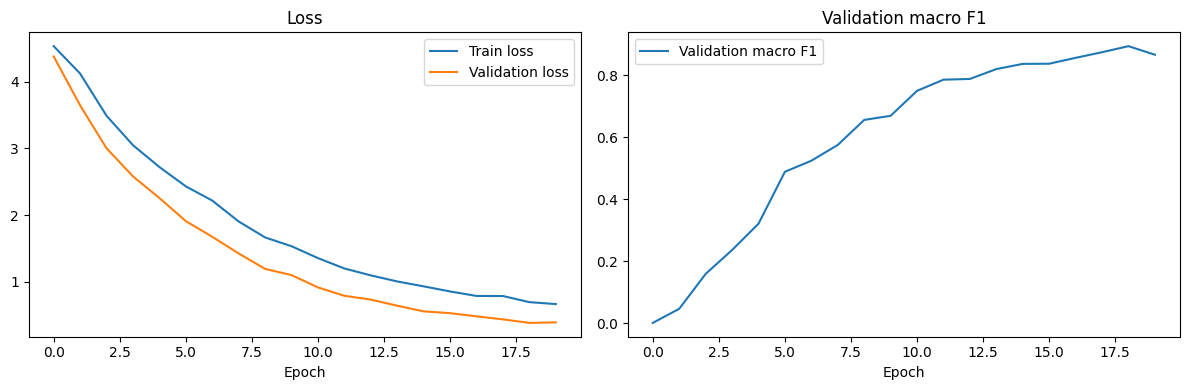

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train loss")
axes[0].plot(history["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["val_macro_f1"], label="Validation macro F1")
axes[1].set_title("Validation macro F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

Powyższe wykresy świadczą o stabilnym procesie trenowania, bez występowania niepokojących sygnałów np. szybkiego plateau czy przeuczania.

# Ewaluacja na validation

In [25]:
val_loss, val_f1, y_true, y_pred = evaluate_model(model, val_loader)

print("CNN BASELINE – WALIDACJA")
print("-" * 45)

print(f"Accuracy:        {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro F1-score:  {val_f1:.4f}")
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall:    {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")

print("\nRaport Klasyfikacji")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

CNN BASELINE – WALIDACJA
---------------------------------------------
Accuracy:        0.8946
Macro F1-score:  0.8946
Macro precision: 0.9115
Macro recall:    0.9000

Raport Klasyfikacji
                       precision    recall  f1-score   support

                  100       1.00      0.71      0.83         7
                Among       1.00      1.00      1.00         9
                Angry       1.00      0.86      0.92        14
                 Ankh       0.88      1.00      0.93         7
               Aroura       1.00      1.00      1.00         7
                   At       1.00      0.86      0.92        14
         Bad_Thinking       1.00      1.00      1.00         8
              Bandage       0.80      0.73      0.76        11
                  Bee       1.00      1.00      1.00         5
              Belongs       0.71      0.83      0.77         6
                Birth       1.00      1.00      1.00         9
           Board_Game       1.00      0.80      0.89   

In [45]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# 1. Zbiorcze metryki
metrics = pd.DataFrame([{
    "Model": "CNN Baseline",
    "Val Loss": val_loss,
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro F1": val_f1,
    "Macro Precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
}])

metrics.to_csv(
    results_dir / "cnn_baseline_metrics.csv",
    index=False
)

# 2. Predykcje dla poszczególnych obrazów
predictions = pd.DataFrame({
    "file_name": val_dataset.df["filename"].tolist(),
    "y_true": y_true,
    "y_pred": y_pred,
    "true_class": [class_names[i] for i in y_true],
    "predicted_class": [class_names[i] for i in y_pred],
    "correct": np.array(y_true) == np.array(y_pred)
})

predictions.to_csv(
    results_dir / "cnn_baseline_predictions.csv",
    index=False
)

# 3. Classification report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    results_dir / "cnn_baseline_classification_report.csv"
)

# Macierz pomyłek

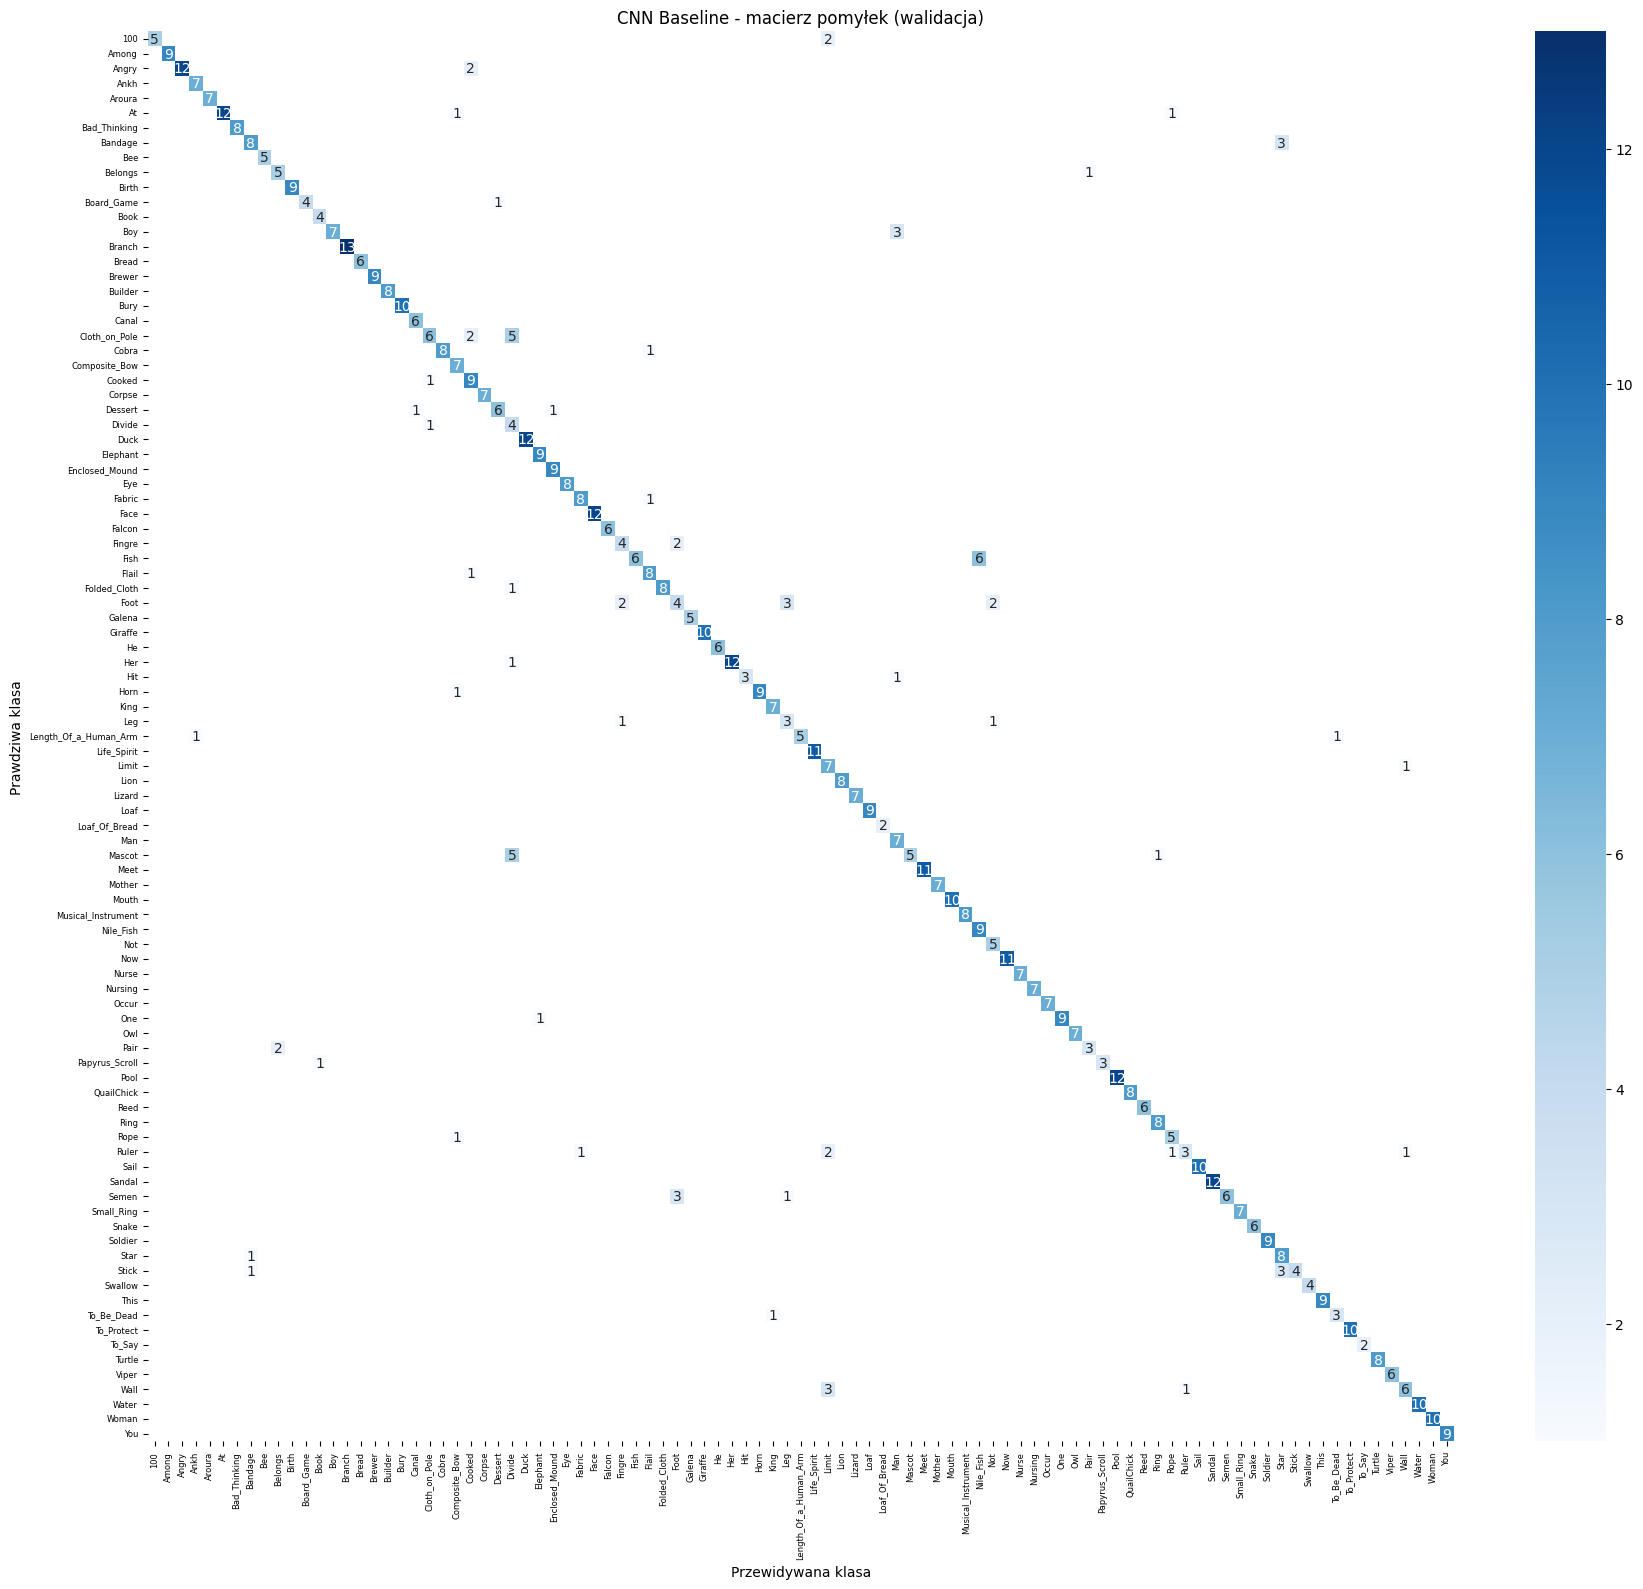

In [35]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    mask=(cm == 0),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)

plt.title("CNN Baseline - macierz pomyłek (walidacja)")
plt.xlabel("Przewidywana klasa")
plt.ylabel("Prawdziwa klasa")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.show()

# Przykłady błędów

Macierz pomyłek jest dosyć trudna do odczytania przy 95 klasach, dlatego dodajmy dodatkowe sprawdzenia najczęstszych pomyłek.

In [42]:
# Wyodrębnienie błędnych klasyfikacji (bez przekątnej)
errors = []

for true_idx in range(len(class_names)):
    for pred_idx in range(len(class_names)):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            errors.append({
                "Prawdziwa klasa": class_names[true_idx],
                "Przewidziana klasa": class_names[pred_idx],
                "Liczba": cm[true_idx, pred_idx]
            })

# Ranking pomyłek
errors_df = pd.DataFrame(errors)

errors_df = errors_df.sort_values(
    by="Liczba",
    ascending=False
).reset_index(drop=True)

# TOP 5 najczęstszych pomyłek
top_errors = errors_df.head(5)

print("TOP 5 NAJCZĘSTSZYCH POMYŁEK - CNN BASELINE")
display(top_errors)


TOP 5 NAJCZĘSTSZYCH POMYŁEK - CNN BASELINE


,Prawdziwa klasa,Przewidziana klasa,Liczba
0,Fish,Nile_Fish,6
1,Mascot,Divide,5
2,Cloth_on_Pole,Divide,5
3,Boy,Man,3
4,Bandage,Star,3


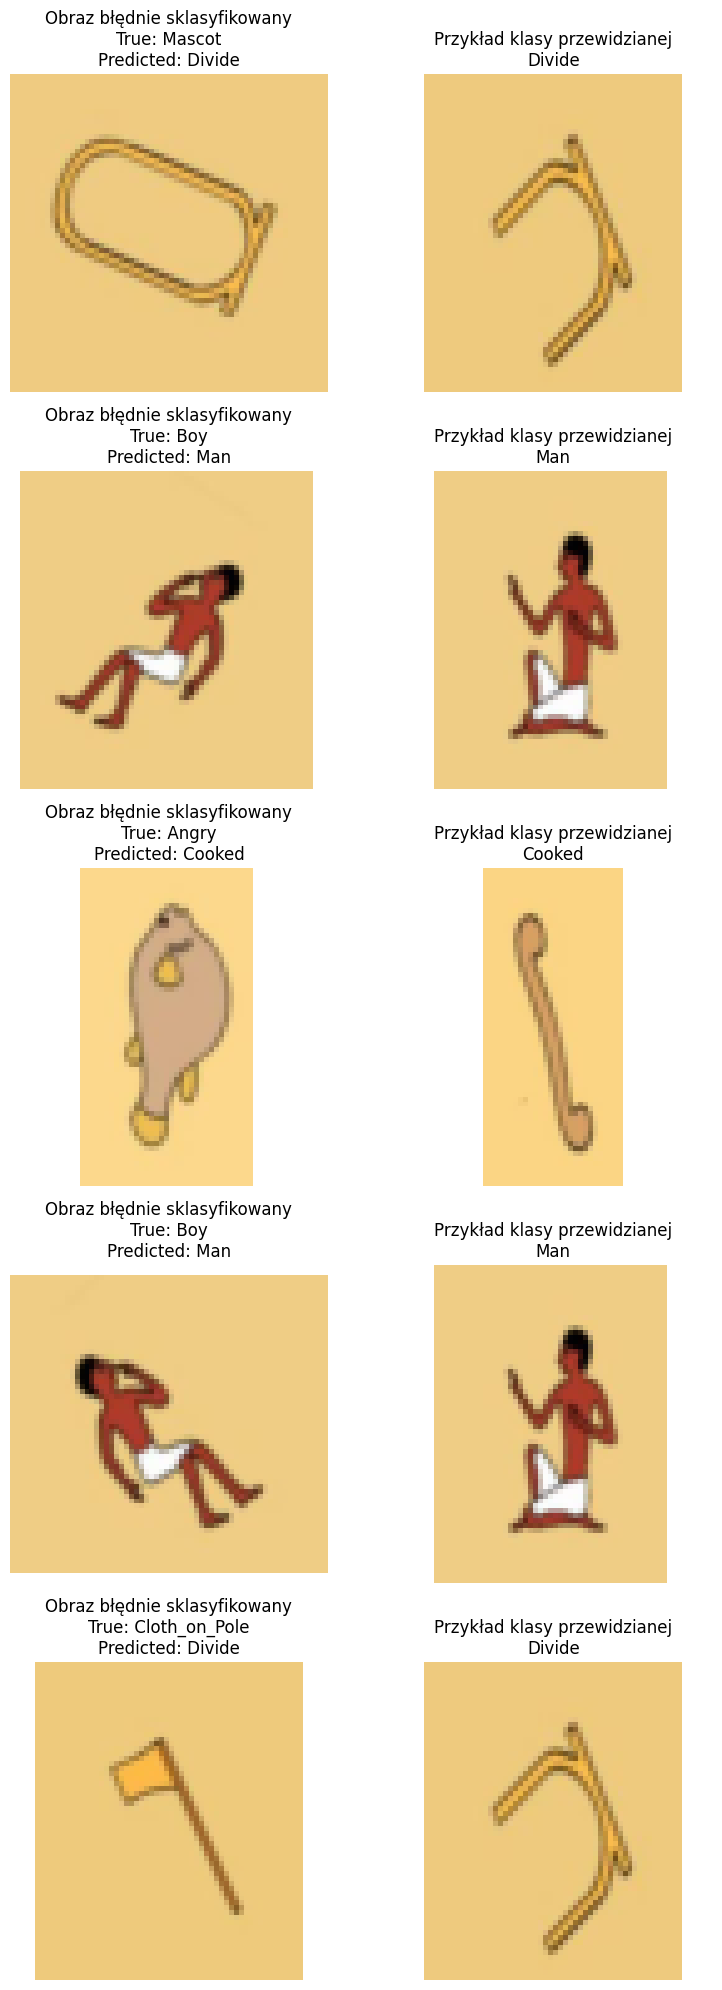

In [40]:
# Indeksy błędnych predykcji
error_indices = np.where(np.array(y_true) != np.array(y_pred))[0]

n_errors = min(5, len(error_indices))

if n_errors == 0:
    print("Brak błędnych predykcji na validation.")

else:
    fig, axes = plt.subplots(
        n_errors, 2,
        figsize=(8, 4 * n_errors)
    )

    if n_errors == 1:
        axes = np.array([axes])

    for row, idx in enumerate(error_indices[:n_errors]):

        image, true_label = val_dataset[idx]
        predicted_label = y_pred[idx]

        # Odwrócenie normalizacji obrazu błędnie sklasyfikowanego
        image = image * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()

        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f"Obraz błędnie sklasyfikowany\n"
            f"True: {class_names[true_label]}\n"
            f"Predicted: {class_names[predicted_label]}"
        )
        axes[row, 0].axis("off")

        # Znalezienie przykładowego obrazu z predicted class
        predicted_sample_idx = next(
            i for i in range(len(val_dataset))
            if val_dataset[i][1] == predicted_label
        )

        predicted_image, _ = val_dataset[predicted_sample_idx]

        predicted_image = predicted_image * 0.5 + 0.5
        predicted_image = predicted_image.permute(1, 2, 0).numpy()

        axes[row, 1].imshow(predicted_image)
        axes[row, 1].set_title(
            f"Przykład klasy przewidzianej\n"
            f"{class_names[predicted_label]}"
        )
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()


Potencjalne problemy modelu zauważalne na przykładach błędów:

1. Trudności z podobnymi klasami: szczególnie Boy i Man, gdzie hieroglify przedstawiają postacie ludzkie o podobnej kolorystykę i elementach ubioru. Model prawdopodobnie rozpoznaje ogólny kształt postaci, ale nie wychwytuje cech pozwalających odróżnić Boy od Man.
2. Niedostateczne rozpoznawanie szczegółów: model może polegać na ogólnym kształcie, a pomijać mniejsze elementy.
3. Ograniczona rozdzielczość obrazów: przy zastosowanym rozmiarze obrazków, drobne cechy charakterystyczne symboli mogą zostać utracone.

# Wnioski z eksperymentu - CNN Baseline
Uzyskane wyniki wskazują, że opracowany model CNN osiąga dobre rezultaty w zadaniu klasyfikacji hieroglifów na zbiorze walidacyjnym. Wysoka wartośc Macro F1-score, oraz zbliżone wartości Macro Precision i Macro Recall wskazują również na stosunkowo dobry balans między poprawnością predykcji a zdolnością do rozpoznawania poszczególnych klas.

Analiza raportu klasyfikacji oraz macierzy pomyłek pokazuje, że model poprawnie rozpoznaje większość klas hieroglifów. Można jednak zauważyć trudności w przypadku niektórych klas, np.
- Boy i Man
- Mascot i Divide oraz Cloth_on_Pole i Divide
- Fish i Nile_Fish

Przegląd pojedynczych błędnych predykcji sugeruje, że jednym z ograniczeń modelu może być trudność w rozpoznawaniu drobnych szczegółów graficznych. Zastosowana rozdzielczość wejściowa 64 x 64 piksele może powodować utratę części informacji wizualnych, natomiast stosunkowo prosta architektura CNN może ograniczać możliwości identyfikowania bardziej złożonych cech i subtelnych różnic między podobnymi klasami.

Podsumowując, eksperyment potwierdził, że nawet stosunkowo prosta architektura CNN pozwala uzyskać dobre wyniki w klasyfikacji hieroglifów. Model stanowi więc użyteczną konfigurację bazową do dalszych eksperymentów. W kolejnej części projektu zostanie zastosowane podejście oparte na transfer learningu, które pozwoli sprawdzić, czy wykorzystanie bardziej zaawansowanej architektury i wcześniej wyuczonych reprezentacji poprawi skuteczność klasyfikacji, szczególnie w przypadku klas sprawiających obecnie największe trudności.